# 特性性能：ARRAY helper · HASH helper · XDP_TX

**读者：** 内部评估 xpost MCU dataplane 相对 HAL 应用路径对照。  
**形态：** 分析笔记本。样式：`default` + Okabe–Ito；中文用系统 **PingFang SC**（避免缺字方框）。

按**特性指标**组织（见 `benchmark/README.md`）：

| 待测特性 | formal 实验 | 主要表 |
|---|---|---|
| ARRAY map helper | `just_drop` | `just_drop_*`，`xdp_agg` / `just_drop_hal_agg` |
| HASH map helper | `firewall` | `firewall_*`，`xdp_agg` / `firewall_hal_agg` |
| `XDP_TX` 回弹 | `just_tx` | `just_tx_*`，`xdp_agg` / `just_tx_hal_agg` |

每张图会保存到 `outputs/feature_perf/`，图下有**数据来源**与**读图分析**。末节对三个 `xdp_t` Trace 画火焰图。

In [ ]:
from __future__ import annotations

import os
import sys
from contextlib import contextmanager
from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager as fm
from IPython.display import display

ROOT = Path.cwd()
if ROOT.name != "benchmark" and (ROOT / "benchmark").is_dir():
    os.chdir(ROOT / "benchmark")
    ROOT = Path.cwd()

os.environ["PGSCHEMA"] = "formal"
sys.path[:0] = [str(ROOT)]
from utils import db  # noqa: E402
from utils.trace_flame import (  # noqa: E402
    HELPER_NAME,
    PROF_SITE,
    TraceEvent,
    action_name,
    frames_from_events,
)

SKILL = ROOT.parent / ".agents" / "skills" / "scientific-visualization"
sys.path[:0] = [str(SKILL / "scripts"), str(SKILL / "assets")]
from style_presets import style_context  # noqa: E402
from color_palettes import OKABE_ITO  # noqa: E402

OUT = ROOT / "outputs" / "feature_perf"
OUT.mkdir(parents=True, exist_ok=True)

# TTC（如 PingFang）在部分 Matplotlib 路径下会缺字/乱距；优先注册单文件 TTF。
_ZH_FILES = [
    Path("/Library/Fonts/Arial Unicode.ttf"),
    Path("/System/Library/Fonts/Supplemental/Arial Unicode.ttf"),
    Path("/System/Library/Fonts/STHeiti Medium.ttc"),
]
_ZH_PATH = next(p for p in _ZH_FILES if p.is_file())
fm.fontManager.addfont(str(_ZH_PATH))
_ZH_NAME = fm.FontProperties(fname=str(_ZH_PATH)).get_name()
print("中文字体:", _ZH_NAME, "->", _ZH_PATH)


@contextmanager
def zh_style():
    with style_context("default", palette_name="okabe_ito_on_white"):
        # style_context 会把 sans 设回 Arial —— 必须在 context 内再覆盖。
        mpl.rcParams["font.family"] = "sans-serif"
        mpl.rcParams["font.sans-serif"] = [_ZH_NAME, "DejaVu Sans"]
        mpl.rcParams["axes.unicode_minus"] = False
        yield


def save_show(fig, stem: str):
    path = OUT / f"{stem}.png"
    fig.savefig(path, dpi=160, facecolor="white")
    print("saved", path)
    plt.show()
    return path


print("DSN:", db.dsn_summary())
COLOR = {
    "xdp": OKABE_ITO["blue"],
    "hal": OKABE_ITO["vermillion"],
    "hit": OKABE_ITO["orange"],
    "miss": OKABE_ITO["bluish_green"],
    "alt": OKABE_ITO["reddish_purple"],
}

中文字体: Arial Unicode MS -> /Library/Fonts/Arial Unicode.ttf
DSN: nan@192.168.110.96:5432/postgres schema=formal


## 0. 实验义务检查

**义务：** `hal` + `xdp_cag` 网格（400…4000 pps、步长 400、窗口 30 s）+ 一次 `xdp_t`。  
`firewall` 另扫 blacklist `{50,100,200}` × `{hit,miss}`。

**选取：** 最新且网格完整、`xdp_t ≥ 1` 的 `exam_id`。

In [ ]:
def pick_exam(config_table: str, min_cag: int, min_hal: int) -> pd.Series:
    q = f"""
    SELECT exam_id::text AS exam_id,
           min(started_at) AS started_at,
           count(*) FILTER (WHERE firmware = 'xdp_cag') AS n_xdp_cag,
           count(*) FILTER (WHERE firmware = 'hal') AS n_hal,
           count(*) FILTER (WHERE firmware = 'xdp_t') AS n_xdp_t
    FROM {config_table}
    GROUP BY exam_id
    HAVING count(*) FILTER (WHERE firmware = 'xdp_cag') >= %s
       AND count(*) FILTER (WHERE firmware = 'hal') >= %s
       AND count(*) FILTER (WHERE firmware = 'xdp_t') >= 1
    ORDER BY min(started_at) DESC
    LIMIT 1
    """
    df = db.read_sql(q, (min_cag, min_hal))
    assert len(df) == 1, f"{config_table} 缺少完整 exam"
    return df.iloc[0]

tx_meta = pick_exam("just_tx_config", 10, 10)
drop_meta = pick_exam("just_drop_config", 10, 10)
fw_meta = pick_exam("firewall_config", 60, 60)
JUST_TX, JUST_DROP, FIREWALL = tx_meta.exam_id, drop_meta.exam_id, fw_meta.exam_id

obligations = pd.DataFrame(
    [
        {"特性": "ARRAY helper", "实验": "just_drop", "exam_id": JUST_DROP,
         "n_xdp_cag": int(drop_meta.n_xdp_cag), "n_hal": int(drop_meta.n_hal),
         "n_xdp_t": int(drop_meta.n_xdp_t), "状态": "通过"},
        {"特性": "HASH helper", "实验": "firewall", "exam_id": FIREWALL,
         "n_xdp_cag": int(fw_meta.n_xdp_cag), "n_hal": int(fw_meta.n_hal),
         "n_xdp_t": int(fw_meta.n_xdp_t), "状态": "通过"},
        {"特性": "XDP_TX", "实验": "just_tx", "exam_id": JUST_TX,
         "n_xdp_cag": int(tx_meta.n_xdp_cag), "n_hal": int(tx_meta.n_hal),
         "n_xdp_t": int(tx_meta.n_xdp_t), "状态": "通过"},
    ]
)
display(obligations)

,特性,实验,exam_id,n_xdp_cag,n_hal,n_xdp_t,状态
0,ARRAY helper,just_drop,18160345-382d-41a6-9589-dc065a474696,10,10,1,通过
1,HASH helper,firewall,37ba80a2-95bd-412b-9407-70159a4c3c2d,60,60,1,通过
2,XDP_TX,just_tx,4a5262ca-5da5-4584-a2ea-69484adeb69f,10,10,1,通过


---
# 1. ARRAY 相关 helper（`just_drop`）

依据 `exam/just_drop.rs`：多源 UDP；ARRAY `counter[末字节]++` 后 DROP。

**仪器：** XDP 有 `map_operation` / `helper_execution`。本轮 HAL `just_drop_hal` 的
`map_operation.count = 0`（未打点）——左图只能用 HAL `execution` 作粗代理。

In [ ]:
def pivot_avg(df: pd.DataFrame, name: str) -> pd.DataFrame:
    return (
        df[df["name"] == name][["target_pps", "avg_ticks", "count"]]
        .sort_values("target_pps")
        .reset_index(drop=True)
    )


def load_agg(config_table: str, agg_table: str, exam_id: str, fw: str) -> pd.DataFrame:
    q = f"""
    SELECT c.target_pps, c.sent, a.name::text AS name, a.count, a.total_ticks,
           CASE WHEN a.count > 0 THEN a.total_ticks::double precision / a.count END AS avg_ticks
    FROM {config_table} c
    JOIN {agg_table} a ON a.config_id = c.id
    WHERE c.exam_id = %s AND c.firmware = %s AND c.window_s > 0
    ORDER BY c.target_pps, a.name
    """
    return db.read_sql(q, (exam_id, fw))


jd_xdp = load_agg("just_drop_config", "xdp_agg", JUST_DROP, "xdp_cag")
jd_hal = load_agg("just_drop_config", "just_drop_hal_agg", JUST_DROP, "hal")

jd = db.read_sql(
    """
    SELECT c.firmware::text AS firmware, c.target_pps, c.sent,
           coalesce(sum(d.value), 0)::bigint AS map_sum,
           coalesce(xc.value, hc.value) AS rx_packets
    FROM just_drop_config c
    LEFT JOIN just_drop_data d ON d.config_id = c.id
    LEFT JOIN xdp_counter xc ON xc.config_id = c.id AND xc.name = 'rx_packets'
    LEFT JOIN just_drop_hal_counter hc ON hc.config_id = c.id AND hc.name = 'rx_packets'
    WHERE c.exam_id = %s AND c.firmware IN ('xdp_cag', 'hal') AND c.window_s > 0
    GROUP BY c.id, c.firmware, c.target_pps, c.sent, xc.value, hc.value
    ORDER BY firmware, target_pps
    """,
    (JUST_DROP,),
)
jd["map_over_sent"] = jd["map_sum"] / jd["sent"].astype(float)
jd["rx_over_sent"] = jd["rx_packets"].astype(float) / jd["sent"].astype(float)
print("HAL map_operation.count:", pivot_avg(jd_hal, "map_operation")["count"].tolist())

HAL map_operation.count: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]


saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/1a_array_map_capture.png


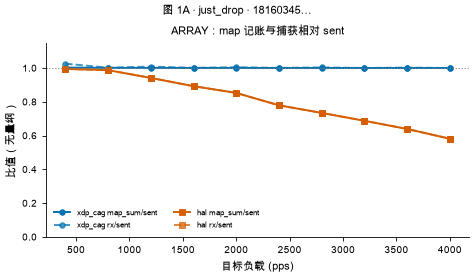

In [ ]:
with zh_style():
    fig, ax = plt.subplots(figsize=(120 / 25.4, 70 / 25.4), layout="constrained")
    for fw, marker, color in [("xdp_cag", "o", COLOR["xdp"]), ("hal", "s", COLOR["hal"])]:
        sub = jd[jd["firmware"] == fw].sort_values("target_pps")
        ax.plot(sub["target_pps"], sub["map_over_sent"], marker=marker, color=color,
                label=f"{fw} map_sum/sent")
        ax.plot(sub["target_pps"], sub["rx_over_sent"], marker=marker, color=color,
                linestyle="--", alpha=0.75, label=f"{fw} rx/sent")
    ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
    ax.set(xlabel="目标负载 (pps)", ylabel="比值（无量纲）", ylim=(0, 1.15),
           title="ARRAY：map 记账与捕获相对 sent")
    ax.legend(ncols=2, fontsize=6)
    fig.suptitle(f"图 1A · just_drop · {JUST_DROP[:8]}…", fontsize=8)
    save_show(fig, "1a_array_map_capture")

### 图 1A 读图分析

**来源：** `just_drop_config.sent` + `Σ just_drop_data.value` + `rx_packets`；exam 见 §0。

- **XDP（蓝）：** `map_sum/sent` 与 `rx/sent` 叠在 ≈1.0，自 400 到 4000 pps 几乎不掉——ARRAY++DROP 路径吃满 offered load。
- **HAL（橙）：** 两线重合且从 ~800 pps 起近似线性下滑，4000 pps 约到 **0.6**。不是「map 算错」，而是应用路径根本收不齐包；map 只是跟着 rx 走。
- **结论：** ARRAY helper 场景下，XDP 的优势首先是**吞吐/捕获**，其次才是单次 helper 更便宜。

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/1b_array_latency.png


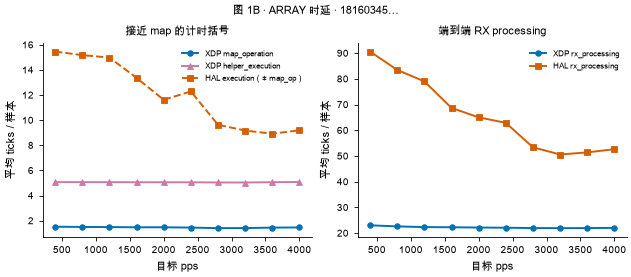

In [ ]:
x_map = pivot_avg(jd_xdp, "map_operation")
x_help = pivot_avg(jd_xdp, "helper_execution")
x_rx = pivot_avg(jd_xdp, "rx_processing")
h_exec = pivot_avg(jd_hal, "execution")
h_rx = pivot_avg(jd_hal, "rx_processing")

with zh_style():
    fig, axes = plt.subplots(1, 2, figsize=(160 / 25.4, 70 / 25.4), layout="constrained")
    ax = axes[0]
    ax.plot(x_map["target_pps"], x_map["avg_ticks"], "o-", color=COLOR["xdp"], label="XDP map_operation")
    ax.plot(x_help["target_pps"], x_help["avg_ticks"], "^-", color=COLOR["alt"], label="XDP helper_execution")
    ax.plot(h_exec["target_pps"], h_exec["avg_ticks"], "s--", color=COLOR["hal"],
            label="HAL execution（≠ map_op）")
    ax.set(xlabel="目标 pps", ylabel="平均 ticks / 样本", title="接近 map 的计时括号")
    ax.legend(fontsize=6)
    ax = axes[1]
    ax.plot(x_rx["target_pps"], x_rx["avg_ticks"], "o-", color=COLOR["xdp"], label="XDP rx_processing")
    ax.plot(h_rx["target_pps"], h_rx["avg_ticks"], "s-", color=COLOR["hal"], label="HAL rx_processing")
    ax.set(xlabel="目标 pps", ylabel="平均 ticks / 样本", title="端到端 RX processing")
    ax.legend(fontsize=6)
    fig.suptitle(f"图 1B · ARRAY 时延 · {JUST_DROP[:8]}…", fontsize=8)
    save_show(fig, "1b_array_latency")

### 图 1B 读图分析

**来源：** `xdp_agg` / `just_drop_hal_agg`；平均 = `total_ticks/count`。

- **左图：** XDP `map_operation` ~1.5 ticks、`helper_execution` ~5 ticks，且对 pps 平坦。HAL `execution` ~10–20 ticks——**不是同一括号**，只能作数量级对照。
- **右图：** XDP `rx_processing` 稳在 ~22 ticks；HAL 从 ~90 降到 ~50 仍远高于 XDP。HAL 均值随 pps「下降」更像是快路径样本占比变化，不能读成「越快越好」。
- **诚实点：** 本轮 HAL 无 `map_operation` 样本；若要严格对比 map 括号，需要给 `just_drop_hal` 补 `record_map_operation`。

---
# 2. HASH 相关 helper（`firewall`）

命中 → ++ 且 DROP；未命中 → PASS / HAL ACK。Firewall HAL 会写 `map_operation`。

In [ ]:
fw = db.read_sql(
    """
    SELECT c.firmware::text AS firmware, c.blacklist_size, c.traffic, c.target_pps, c.sent,
           coalesce((SELECT sum(d.value) FROM firewall_data d WHERE d.config_id = c.id), 0)::bigint AS map_sum,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM xdp_agg a WHERE a.config_id = c.id AND a.name = 'map_operation') AS xdp_map_ticks,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM xdp_agg a WHERE a.config_id = c.id AND a.name = 'rx_processing') AS xdp_rx_ticks,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM firewall_hal_agg a WHERE a.config_id = c.id AND a.name = 'map_operation') AS hal_map_ticks,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM firewall_hal_agg a WHERE a.config_id = c.id AND a.name = 'rx_processing') AS hal_rx_ticks
    FROM firewall_config c
    WHERE c.exam_id = %s AND c.firmware IN ('xdp_cag', 'hal') AND c.window_s > 0
    ORDER BY firmware, blacklist_size, traffic, target_pps
    """,
    (FIREWALL,),
)
fw["map_over_sent"] = fw["map_sum"] / fw["sent"].astype(float)
fw["map_ticks"] = fw["xdp_map_ticks"].fillna(fw["hal_map_ticks"])
fw["rx_ticks"] = fw["xdp_rx_ticks"].fillna(fw["hal_rx_ticks"])

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/2a_hash_map_ratio.png


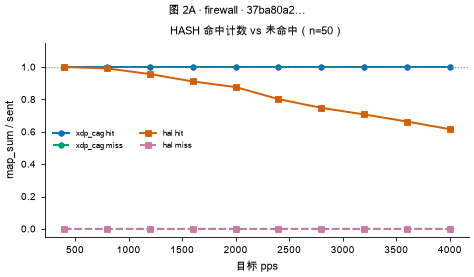

In [ ]:
sub50 = fw[fw["blacklist_size"] == 50].copy()
with zh_style():
    fig, ax = plt.subplots(figsize=(120 / 25.4, 70 / 25.4), layout="constrained")
    styles = {
        ("xdp_cag", "hit"): ("o-", COLOR["xdp"]),
        ("xdp_cag", "miss"): ("o--", COLOR["miss"]),
        ("hal", "hit"): ("s-", COLOR["hal"]),
        ("hal", "miss"): ("s--", COLOR["alt"]),
    }
    for key, (fmt, col) in styles.items():
        s = sub50[(sub50["firmware"] == key[0]) & (sub50["traffic"] == key[1])].sort_values("target_pps")
        ax.plot(s["target_pps"], s["map_over_sent"], fmt, color=col, label=f"{key[0]} {key[1]}")
    ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
    ax.set(xlabel="目标 pps", ylabel="map_sum / sent", ylim=(-0.05, 1.15),
           title="HASH 命中计数 vs 未命中（n=50）")
    ax.legend(fontsize=6, ncols=2)
    fig.suptitle(f"图 2A · firewall · {FIREWALL[:8]}…", fontsize=8)
    save_show(fig, "2a_hash_map_ratio")

### 图 2A 读图分析

**来源：** `firewall_config` + `Σ firewall_data.value`，`blacklist_size=50`。

- **XDP hit：** 全网格 `map_sum/sent = 1.0`——每个刺激包都让命中键 +1。
- **XDP / HAL miss：** 贴 0——未命中键不被 ++，语义正确。
- **HAL hit：** 低 pps 接近 1，随后下滑到 ~0.6（4000 pps）——应用侧查表丢弃跟不上，**计数丢失先于「查表变慢」**。
- **结论：** HASH 命中记账上 XDP 在持续负载下明显更稳；HAL 仍适合低速率功能对照。

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/2b_hash_map_ticks.png


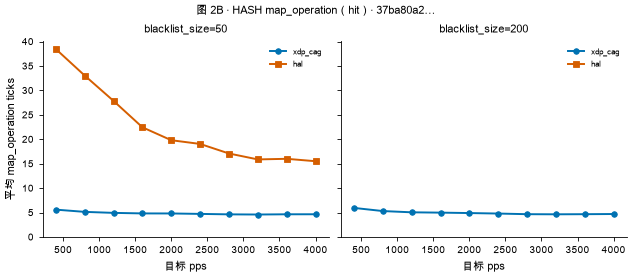

In [ ]:
hit = fw[fw["traffic"] == "hit"]
with zh_style():
    fig, axes = plt.subplots(1, 2, figsize=(160 / 25.4, 70 / 25.4), layout="constrained", sharey=True)
    for ax, size in zip(axes, [50, 200]):
        for fw_name, marker, color in [("xdp_cag", "o", COLOR["xdp"]), ("hal", "s", COLOR["hal"])]:
            s = hit[(hit["firmware"] == fw_name) & (hit["blacklist_size"] == size)].sort_values("target_pps")
            ax.plot(s["target_pps"], s["map_ticks"], marker=marker, color=color, label=fw_name)
        ax.set(xlabel="目标 pps", title=f"blacklist_size={size}")
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=6)
    axes[0].set_ylabel("平均 map_operation ticks")
    fig.suptitle(f"图 2B · HASH map_operation（hit）· {FIREWALL[:8]}…", fontsize=8)
    save_show(fig, "2b_hash_map_ticks")

### 图 2B 读图分析

**来源：** hit 路径的 `map_operation` 平均 ticks；对比 size=50 与 200。

- **XDP：** ~5 ticks，两条 size 曲线几乎重合——在 `max_entries=256` 下，50→200 未拉开 HASH 成本。
- **HAL：** ~15–40 ticks，低 pps 更高（固定开销占比大），整体仍数倍于 XDP。
- **读法：** 单次 lookup+inc XDP 更便宜；但结合图 2A，HAL 高负载的主矛盾是**丢包导致计数不全**，不只是每操 ticks。

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/2c_hash_hit_miss_rx.png


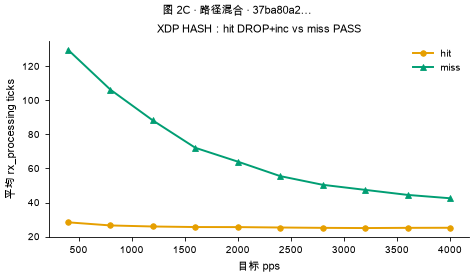

In [ ]:
xdp50 = fw[(fw["firmware"] == "xdp_cag") & (fw["blacklist_size"] == 50)]
with zh_style():
    fig, ax = plt.subplots(figsize=(120 / 25.4, 70 / 25.4), layout="constrained")
    for tr, color, marker in [("hit", COLOR["hit"], "o"), ("miss", COLOR["miss"], "^")]:
        s = xdp50[xdp50["traffic"] == tr].sort_values("target_pps")
        ax.plot(s["target_pps"], s["rx_ticks"], marker=marker, color=color, label=tr)
    ax.set(xlabel="目标 pps", ylabel="平均 rx_processing ticks",
           title="XDP HASH：hit DROP+inc vs miss PASS")
    ax.legend()
    fig.suptitle(f"图 2C · 路径混合 · {FIREWALL[:8]}…", fontsize=8)
    save_show(fig, "2c_hash_hit_miss_rx")

### 图 2C 读图分析

**来源：** 仅 `xdp_cag`、`n=50` 的 `rx_processing`。

- **低 pps：** miss（PASS 进栈）远高于 hit（DROP）——栈交付主导。
- **高 pps：** miss 曲线下降，**不是 lookup 变快**，而是昂贵的 PASS/栈路径被拥塞「挤掉」，平均被快路径样本拉低。
- hit 曲线平坦 ~25 ticks，与「查表+DROP」成本稳定一致。

---
# 3. XDP_TX 相关性能（`just_tx`）

带序号 UDP；XDP `XDP_TX`；主机 RTT 在 `just_tx_data`。丢包 = `sent - ok`。

In [ ]:
tx = db.read_sql(
    """
    SELECT c.firmware::text AS firmware, c.target_pps, c.sent, c.ok,
           (SELECT value FROM xdp_counter x WHERE x.config_id = c.id AND x.name = 'xdp_tx') AS xdp_tx,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM xdp_agg a WHERE a.config_id = c.id AND a.name = 'rx_processing') AS xdp_rx,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM xdp_agg a WHERE a.config_id = c.id AND a.name = 'tx_submission') AS xdp_tx_sub,
           (SELECT CASE WHEN a.count > 0 THEN a.total_ticks::float/a.count END
              FROM just_tx_hal_agg a WHERE a.config_id = c.id AND a.name = 'rx_processing') AS hal_rx
    FROM just_tx_config c
    WHERE c.exam_id = %s AND c.firmware IN ('xdp_cag', 'hal') AND c.window_s > 0
    ORDER BY firmware, target_pps
    """,
    (JUST_TX,),
)
tx["ok_ratio"] = tx["ok"] / tx["sent"].astype(float)
tx["tx_over_sent"] = tx["xdp_tx"] / tx["sent"].astype(float)

rtt = db.read_sql(
    """
    SELECT c.firmware::text AS firmware, c.target_pps,
           percentile_cont(0.5) WITHIN GROUP (
             ORDER BY EXTRACT(EPOCH FROM (d.t_rx - d.t_tx)) * 1e6) AS p50_us,
           percentile_cont(0.95) WITHIN GROUP (
             ORDER BY EXTRACT(EPOCH FROM (d.t_rx - d.t_tx)) * 1e6) AS p95_us,
           count(*)::bigint AS n_ok_samples
    FROM just_tx_config c
    JOIN just_tx_data d ON d.config_id = c.id
    WHERE c.exam_id = %s AND c.firmware IN ('xdp_cag', 'hal') AND c.window_s > 0
    GROUP BY c.firmware, c.target_pps
    ORDER BY firmware, target_pps
    """,
    (JUST_TX,),
)
tx = tx.merge(rtt, on=["firmware", "target_pps"], how="left")

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/3a_tx_ok_ratio.png


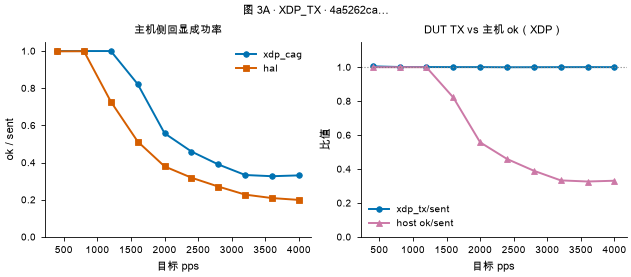

In [ ]:
with zh_style():
    fig, axes = plt.subplots(1, 2, figsize=(160 / 25.4, 70 / 25.4), layout="constrained")
    ax = axes[0]
    for fw_name, marker, color in [("xdp_cag", "o", COLOR["xdp"]), ("hal", "s", COLOR["hal"])]:
        s = tx[tx["firmware"] == fw_name].sort_values("target_pps")
        ax.plot(s["target_pps"], s["ok_ratio"], marker=marker, color=color, label=fw_name)
    ax.set(xlabel="目标 pps", ylabel="ok / sent", ylim=(0, 1.05), title="主机侧回显成功率")
    ax.legend()
    ax = axes[1]
    s = tx[tx["firmware"] == "xdp_cag"].sort_values("target_pps")
    ax.plot(s["target_pps"], s["tx_over_sent"], "o-", color=COLOR["xdp"], label="xdp_tx/sent")
    ax.plot(s["target_pps"], s["ok_ratio"], "^-", color=COLOR["alt"], label="host ok/sent")
    ax.axhline(1.0, color="0.5", lw=0.8, ls=":")
    ax.set(xlabel="目标 pps", ylabel="比值", ylim=(0, 1.15), title="DUT TX vs 主机 ok（XDP）")
    ax.legend()
    fig.suptitle(f"图 3A · XDP_TX · {JUST_TX[:8]}…", fontsize=8)
    save_show(fig, "3a_tx_ok_ratio")

### 图 3A 读图分析

**来源：** `just_tx_config.{sent,ok}`；右图另加 `xdp_counter.xdp_tx`。

- **左图：** XDP 的 `ok/sent` 在 ≤1200 pps 仍为 1.0，之后下滑；HAL 从 ~1200 起更早、更陡地掉到 ~0.2。
- **右图：** 高 pps 时 `xdp_tx/sent≈1` 而 `ok/sent` 已明显更低——DUT 仍在 TX，丢失发生在**回程/主机核对**，不是 dataplane 停发。
- **结论：** XDP_TX 在「还能回得来」的负载区优于 HAL；过载后两边都受无线/主机侧限制。

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/3b_tx_rtt.png


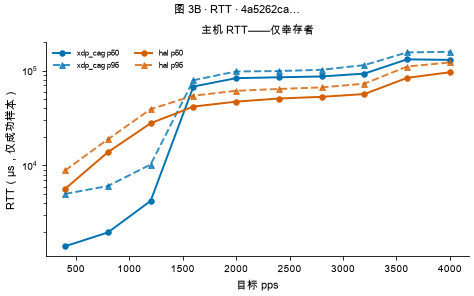

In [ ]:
with zh_style():
    fig, ax = plt.subplots(figsize=(120 / 25.4, 75 / 25.4), layout="constrained")
    for fw_name, color in [("xdp_cag", COLOR["xdp"]), ("hal", COLOR["hal"])]:
        s = tx[tx["firmware"] == fw_name].sort_values("target_pps")
        ax.plot(s["target_pps"], s["p50_us"], "o-", color=color, label=f"{fw_name} p50")
        ax.plot(s["target_pps"], s["p95_us"], "^--", color=color, alpha=0.8, label=f"{fw_name} p95")
    ax.set(xlabel="目标 pps", ylabel="RTT（µs，仅成功样本）",
           title="主机 RTT——仅幸存者", yscale="log")
    ax.legend(ncols=2, fontsize=6)
    fig.suptitle(f"图 3B · RTT · {JUST_TX[:8]}…", fontsize=8)
    save_show(fig, "3b_tx_rtt")

### 图 3B 读图分析

**来源：** `just_tx_data` 上 RTT 的 p50/p95；纵轴 log；**仅成功样本**。

- 低负载：XDP p50 约 1–4 ms 量级，明显低于 HAL（数 ms 起）。
- ≥1600 pps：XDP p50 跳到数十 ms，与 ok 下降同步——队列/无线拥塞。
- **偏差：** 高 pps 分位数只描述幸存者，不能外推到全部 sent。

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/3c_tx_device_cag.png


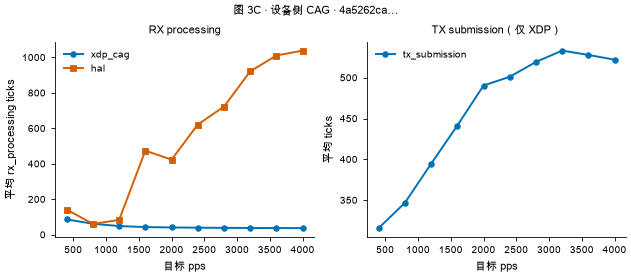

In [ ]:
with zh_style():
    fig, axes = plt.subplots(1, 2, figsize=(160 / 25.4, 70 / 25.4), layout="constrained")
    ax = axes[0]
    for fw_name, marker, color, col in [
        ("xdp_cag", "o", COLOR["xdp"], "xdp_rx"),
        ("hal", "s", COLOR["hal"], "hal_rx"),
    ]:
        s = tx[tx["firmware"] == fw_name].sort_values("target_pps")
        ax.plot(s["target_pps"], s[col], marker=marker, color=color, label=fw_name)
    ax.set(xlabel="目标 pps", ylabel="平均 rx_processing ticks", title="RX processing")
    ax.legend()
    ax = axes[1]
    s = tx[tx["firmware"] == "xdp_cag"].sort_values("target_pps")
    ax.plot(s["target_pps"], s["xdp_tx_sub"], "o-", color=COLOR["xdp"], label="tx_submission")
    ax.set(xlabel="目标 pps", ylabel="平均 ticks", title="TX submission（仅 XDP）")
    ax.legend()
    fig.suptitle(f"图 3C · 设备侧 CAG · {JUST_TX[:8]}…", fontsize=8)
    save_show(fig, "3c_tx_device_cag")

### 图 3C 读图分析

**来源：** `xdp_agg.rx_processing` / `tx_submission`；`just_tx_hal_agg.rx_processing`。

- 左：HAL `rx_processing` 随 pps 升到数百～千 ticks；XDP 侧均值反而下降——样本混合变化，需结合 ok 一起看。
- 右：XDP `tx_submission` 达**数百 ticks**，相对 RX 括号是 XDP_TX 设备侧主成本（DMA/kick），不是 map helper。

---
# 4. 三个实验的 `xdp_t` 火焰图

数据：`formal.trace_event`（formal 写入时 kind 为 snake_case）。  
解析：转成 `utils.trace_flame.TraceEvent` 后用 `frames_from_events` 得到嵌套区间，
再画绝对时间轴上的火焰条（深度 = 嵌套层）。

**注意：** formal Trace 是单包/少包快照，不是持续高 pps 火焰；用于看路径结构与关键段 µs。

In [ ]:
# SQL snake_case → trace_flame 期望的 CamelCase
_KIND = {
    "rx_begin": "RxBegin",
    "xdp_begin": "XdpBegin",
    "xdp_end": "XdpEnd",
    "rx_end": "RxEnd",
    "span_begin": "SpanBegin",
    "span_end": "SpanEnd",
    "helper_enter": "HelperEnter",
    "helper_leave": "HelperLeave",
    "rx_delivered": "RxDelivered",
    "rx_discarded": "RxDiscarded",
    "tx_sub_begin": "TxSubBegin",
    "tx_submitted": "TxSubmitted",
    "tx_failed": "TxFailed",
    "tx_completed": "TxCompleted",
    "tx_enq": "TxEnq",
    "tx_kick": "TxKick",
    "tx_poll": "TxPoll",
    "tx_block": "TxBlock",
    "tx_no_retain": "TxNoRetain",
}


def load_trace(exam_id: str) -> pd.DataFrame:
    return db.read_sql(
        """
        SELECT seq, kind::text AS kind, t_us, arg0, arg1
        FROM trace_event
        WHERE exam_id = %s
        ORDER BY seq
        """,
        (exam_id,),
    )


def to_events(df: pd.DataFrame) -> list[TraceEvent]:
    out: list[TraceEvent] = []
    for r in df.itertuples(index=False):
        k = _KIND.get(r.kind)
        if k is None:
            # 保留未知 kind 的原始名（大写首字母拼接）以便点事件可见
            k = "".join(p.title() for p in r.kind.split("_"))
        out.append(TraceEvent(kind=k, t_us=int(r.t_us), arg0=int(r.arg0), arg1=int(r.arg1)))
    return out


def _split_episodes(evs: list[TraceEvent], gap_us: int = 1000) -> list[list[TraceEvent]]:
    """按事件间隔切开连续路径，避免 just_tx 多包跨数百 ms 挤在一张图上。"""
    if not evs:
        return []
    ordered = sorted(evs, key=lambda e: e.t_us)
    eps: list[list[TraceEvent]] = [[ordered[0]]]
    for e in ordered[1:]:
        if e.t_us - eps[-1][-1].t_us > gap_us:
            eps.append([e])
        else:
            eps[-1].append(e)
    return eps


def _draw_flame_ax(ax, frames, t0: int, region_color: dict):
    for f in frames:
        w = max(f.t1_us - f.t0_us, 0.5)
        ax.barh(
            y=f.depth,
            width=w,
            left=f.t0_us - t0,
            height=0.8,
            color=region_color.get(f.region, "0.5"),
            edgecolor="white",
            linewidth=0.3,
            align="center",
        )
        if w >= 2:
            ax.text(
                f.t0_us - t0 + w / 2,
                f.depth,
                f"{f.name} {f.t1_us - f.t0_us}µs",
                ha="center",
                va="center",
                fontsize=6,
                color="white" if f.region == "inside_xdp" else "black",
            )


def plot_flame(exam_id: str, title: str, stem: str):
    df = load_trace(exam_id)
    evs = to_events(df)
    episodes = _split_episodes(evs, gap_us=1000)
    region_color = {
        "inside_xdp": COLOR["xdp"],
        "outside_xdp": COLOR["hal"],
        "post_xdp": COLOR["alt"],
    }
    all_frames = []
    drawn = 0
    for ei, ep in enumerate(episodes):
        frames = frames_from_events(ep)
        if not frames:
            continue
        all_frames.extend(frames)
        t0 = min(f.t0_us for f in frames)
        t1 = max(f.t1_us for f in frames)
        max_d = max(f.depth for f in frames)
        actions = [action_name(e.arg0) for e in ep if e.kind == "XdpEnd"]
        with zh_style():
            fig, ax = plt.subplots(
                figsize=(160 / 25.4, 14 / 25.4 * (max_d + 3)),
                layout="constrained",
            )
            _draw_flame_ax(ax, frames, t0, region_color)
            ax.set_ylim(max_d + 0.8, -0.8)
            ax.set_xlabel("相对时间 (µs，自本段最早帧)")
            ax.set_ylabel("嵌套深度")
            act = ",".join(actions) if actions else "—"
            ax.set_title(
                f"{title} · 片段 {ei+1}/{len(episodes)} · 跨度 {t1 - t0} µs · "
                f"帧 {len(frames)} · XdpEnd=[{act}]"
            )
            fig.suptitle(f"火焰图 · exam {exam_id[:8]}…", fontsize=8)
            save_show(fig, f"{stem}_ep{ei+1}")
            drawn += 1

    if drawn == 0:
        print(title, "无闭区间帧，事件数=", len(evs))
        display(df)
        return df, all_frames

    summary = pd.DataFrame(
        sorted(
            [
                {"name": f.name, "depth": f.depth, "dur_us": f.t1_us - f.t0_us, "region": f.region}
                for f in all_frames
            ],
            key=lambda r: (-r["dur_us"], r["depth"]),
        )
    )
    display(summary.head(16))
    for e in evs:
        if e.kind == "XdpEnd":
            print("XdpEnd action =", e.arg0, action_name(e.arg0))
    return df, all_frames


print("PROF_SITE", PROF_SITE)
print("HELPER", HELPER_NAME)

PROF_SITE {0: 'XdpRun', 1: 'TxEnqueue', 2: 'TxDrainOne', 3: 'TxDrainBatch', 4: 'WifiRxDispatch', 5: 'TxSubmit'}
HELPER {1: 'map_lookup', 2: 'map_update', 3: 'map_delete', 5: 'ktime_get_ns', 6: 'trace_printk', 28: 'csum_diff', 65: 'adjust_tail'}


=== just_drop xdp_t ===
saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/flame_just_drop_ep1.png


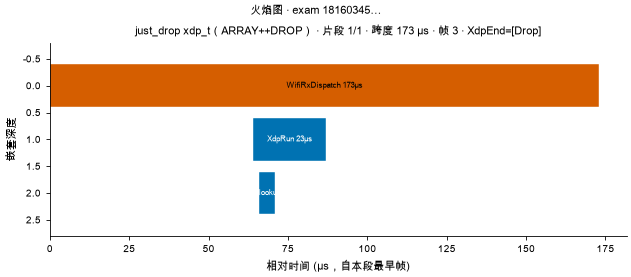

,name,depth,dur_us,region
0,WifiRxDispatch,0,173,outside_xdp
1,XdpRun,1,23,inside_xdp
2,map_lookup,2,5,inside_xdp


XdpEnd action = 1 Drop


In [ ]:
print("=== just_drop xdp_t ===")
drop_tr, drop_fr = plot_flame(JUST_DROP, "just_drop xdp_t（ARRAY++DROP）", "flame_just_drop")

### 火焰图 just_drop 读图分析

单包 Trace（ARRAY++DROP）：

| 帧 | 时长 | 含义 |
|---|---|---|
| WifiRxDispatch | ~173 µs | 整段 RX 调度外壳 |
| XdpRun | ~23 µs | AOT XDP 主体（约占总调度 13%） |
| map_lookup | ~5 µs | ARRAY 查表 helper |

`XdpEnd=Drop` 与实验语义一致。大部分时间花在 **WifiRxDispatch 外壳**（进/出 XDP 前后），
不是 map helper 本身——和 CAG 里「map_operation 很便宜、rx_processing 含更多」一致。

=== firewall xdp_t ===
saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/flame_firewall_ep1.png


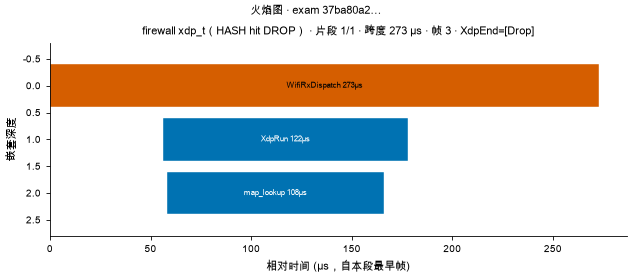

,name,depth,dur_us,region
0,WifiRxDispatch,0,273,outside_xdp
1,XdpRun,1,122,inside_xdp
2,map_lookup,2,108,inside_xdp


XdpEnd action = 1 Drop


In [ ]:
print("=== firewall xdp_t ===")
fw_tr, fw_fr = plot_flame(FIREWALL, "firewall xdp_t（HASH hit DROP）", "flame_firewall")

### 火焰图 firewall 读图分析

单包 Trace（HASH hit → DROP）：

| 帧 | 时长 | 含义 |
|---|---|---|
| WifiRxDispatch | ~273 µs | RX 调度外壳 |
| XdpRun | ~122 µs | XDP 主体 |
| map_lookup | ~108 µs | HASH lookup（占 XdpRun 约 88%） |

与 just_drop 对比：同一 helper 名 `map_lookup`，HASH 路径这次 **~108 µs**，ARRAY 仅 **~5 µs**。
说明 Trace 快照里 HASH 命中路径明显更重（含 ++/写回与 hash 探测）；CAG 网格平均 ~5 ticks
是大量样本上的均值，单位/括号不同，**不能直接把 µs 与 ticks 划等号**，但方向一致：HASH 比 ARRAY 贵。
`XdpEnd=Drop` 正确。

=== just_tx xdp_t ===
saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/flame_just_tx_ep1.png


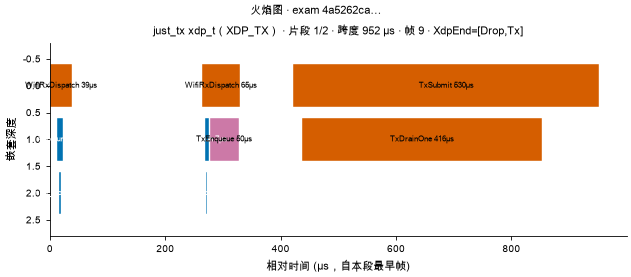

saved /Volumes/SSD/bs/xpost/benchmark/outputs/feature_perf/flame_just_tx_ep2.png


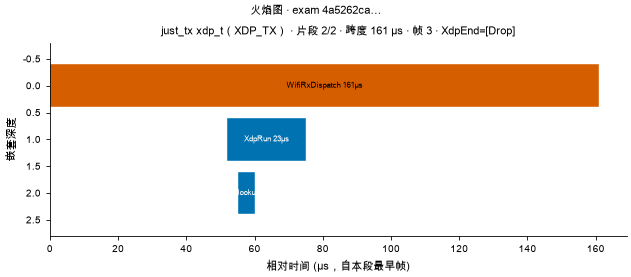

,name,depth,dur_us,region
0,TxSubmit,0,530,outside_xdp
1,TxDrainOne,1,416,outside_xdp
2,WifiRxDispatch,0,161,outside_xdp
3,WifiRxDispatch,0,65,outside_xdp
4,TxEnqueue,1,50,post_xdp
5,WifiRxDispatch,0,39,outside_xdp
6,XdpRun,1,23,inside_xdp
7,XdpRun,1,11,inside_xdp
8,XdpRun,1,7,inside_xdp
9,map_lookup,2,5,inside_xdp


XdpEnd action = 1 Drop
XdpEnd action = 3 Tx
XdpEnd action = 1 Drop


In [ ]:
print("=== just_tx xdp_t ===")
tx_tr, tx_fr = plot_flame(JUST_TX, "just_tx xdp_t（XDP_TX）", "flame_just_tx")

### 火焰图 just_tx 读图分析

formal `xdp_t` 含多段活动（噪声 DROP + 真正 TX + 异步 TxSubmit），按 >1 ms 间隙拆成多张子图：

1. **噪声 RX：** 有的片段 `XdpEnd=Drop`（非刺激/解析失败），`map_lookup` 仍出现但很短。
2. **刺激 TX 片段：** `XdpEnd=Tx`；其前后可见 `TxEnqueue`（post_xdp）以及稍后的
   `TxSubmit` / `TxDrainOne`（数百 µs 量级）——与图 3C 中 `tx_submission` 昂贵一致。
3. **时间尺度：** 整段 wall 可达数十万 µs，但有效工作仍是百 µs 级 burst；火焰图应按片段看，
   不要被空白间隔拉扁。

**结论：** XDP_TX 的 dataplane 热路径不在 map helper，而在 **TX enqueue/submit/drain**；
map_lookup 只占 XdpRun 内很小一块。

---
# 5. 跨特性结论（诚实）

| 特性 | XDP 优势 | 注意事项 / HAL |
|---|---|---|
| ARRAY helper | 高 pps 仍能 `map≈sent`；更低 rx_processing | HAL 丢捕获；无 map_operation 样本 |
| HASH helper | hit 记账满格；map_op ~5 ticks | HAL hit 随负载掉；miss 两边都接近 0 |
| XDP_TX | ok 平台更高；拥塞前 RTT 更低 | 过载后回程丢失；TX submission 仍贵 |

图文件目录：`benchmark/outputs/feature_perf/`。